# ECE 3715 Mini-Project 3

## Team Members
- Trevor Cheng: Steps 1–3, Bonus A, selected library functions
- George Li: Steps 4–6, Bonus B, selected library functions
- Andrew Ore: Steps 7–8, final integration and testing

## Seed
SEED = 836285155 (Nov 18, 2026)

## Runtime
To be recorded after the final clean-kernel run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate
from scipy.stats import multivariate_normal
import time

from mp3lib import (
    sample_mean_cov,
    is_valid_covariance,
    gaussian_pdf,
    whitening_matrix,
    lmmse_weights
)

SEED = 836285155
rng = np.random.default_rng(SEED)

rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]

rng_bonus_A = rng.spawn(1)[0]
rng_bonus_B = rng.spawn(1)[0]

runtime_start = time.perf_counter()

# Step 1: Two Variables at Once

We study the joint density

$$
f_{X,Y}(x,y)=x+y,\qquad 0\le x\le1,\;0\le y\le1.
$$

The goal is to verify its normalization, marginals, conditional density, moments, covariance, correlation, and Monte Carlo behavior.

## Analytical Results

Normalization:

$$
\int_0^1\int_0^1(x+y)\,dy\,dx=1,
$$

so \(f_{X,Y}\) is a valid density.

The marginals are

$$
f_X(x)=\int_0^1(x+y)\,dy=x+\frac12,
$$

$$
f_Y(y)=\int_0^1(x+y)\,dx=y+\frac12.
$$

The conditional density is

$$
f_{Y|X}(y|x)=\frac{x+y}{x+\frac12}.
$$

At \(x=0.3\),

$$
f_{Y|X}(y|0.3)=\frac{0.3+y}{0.8}.
$$

The analytical moments are

$$
E[X]=E[Y]=\frac{7}{12},
\qquad
E[XY]=\frac13,
$$

$$
\operatorname{Var}(X)=\operatorname{Var}(Y)=\frac{11}{144},
$$

$$
\operatorname{Cov}(X,Y)=-\frac1{144},
\qquad
\rho_{X,Y}=-\frac1{11}.
$$

In [2]:
def joint_xy(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    inside = (0 <= x) & (x <= 1) & (0 <= y) & (y <= 1)
    return np.where(inside, x + y, 0.0)


def quad2d(function):
    return integrate.dblquad(
        lambda y, x: function(x, y),
        0, 1,
        lambda x: 0,
        lambda x: 1,
        epsabs=1e-12,
        epsrel=1e-12
    )


quadrature_results = {
    "Normalization": quad2d(lambda x, y: joint_xy(x, y)),
    "E[X]": quad2d(lambda x, y: x * joint_xy(x, y)),
    "E[Y]": quad2d(lambda x, y: y * joint_xy(x, y)),
    "E[XY]": quad2d(lambda x, y: x * y * joint_xy(x, y)),
    "E[X^2]": quad2d(lambda x, y: x**2 * joint_xy(x, y)),
    "E[Y^2]": quad2d(lambda x, y: y**2 * joint_xy(x, y)),
}

for name, (value, error) in quadrature_results.items():
    print(f"{name}: {value:.12f}, quadrature error estimate: {error:.3e}")

ex_quad = quadrature_results["E[X]"][0]
ey_quad = quadrature_results["E[Y]"][0]
exy_quad = quadrature_results["E[XY]"][0]
ex2_quad = quadrature_results["E[X^2]"][0]
ey2_quad = quadrature_results["E[Y^2]"][0]

var_x_quad = ex2_quad - ex_quad**2
var_y_quad = ey2_quad - ey_quad**2
cov_xy_quad = exy_quad - ex_quad * ey_quad
rho_quad = cov_xy_quad / np.sqrt(var_x_quad * var_y_quad)

print(f"Var(X): {var_x_quad:.12f}")
print(f"Var(Y): {var_y_quad:.12f}")
print(f"Cov(X,Y): {cov_xy_quad:.12f}")
print(f"Correlation: {rho_quad:.12f}")

Normalization: 1.000000000000, quadrature error estimate: 1.663e-14
E[X]: 0.583333333333, quadrature error estimate: 1.659e-14
E[Y]: 0.583333333333, quadrature error estimate: 9.240e-15
E[XY]: 0.333333333333, quadrature error estimate: 9.220e-15
E[X^2]: 0.416666666667, quadrature error estimate: 1.656e-14
E[Y^2]: 0.416666666667, quadrature error estimate: 6.468e-15
Var(X): 0.076388888889
Var(Y): 0.076388888889
Cov(X,Y): -0.006944444444
Correlation: -0.090909090909


In [3]:
grid = np.linspace(0, 1, 501)
X_grid, Y_grid = np.meshgrid(grid, grid, indexing="ij")
joint_grid = joint_xy(X_grid, Y_grid)

fX_numeric = integrate.trapezoid(joint_grid, grid, axis=1)
fY_numeric = integrate.trapezoid(joint_grid, grid, axis=0)

fX_analytic = grid + 0.5
fY_analytic = grid + 0.5

x_condition = 0.3
conditional_grid = (x_condition + grid) / (x_condition + 0.5)

conditional_integral, conditional_error = integrate.quad(
    lambda y: (x_condition + y) / (x_condition + 0.5),
    0, 1
)

print(f"Conditional integral at x=0.3: {conditional_integral:.12f}")
print(f"Conditional quadrature error: {conditional_error:.3e}")
print(f"Maximum fX grid error: {np.max(np.abs(fX_numeric - fX_analytic)):.3e}")
print(f"Maximum fY grid error: {np.max(np.abs(fY_numeric - fY_analytic)):.3e}")

Conditional integral at x=0.3: 1.000000000000
Conditional quadrature error: 1.110e-14
Maximum fX grid error: 2.220e-16
Maximum fY grid error: 8.882e-16


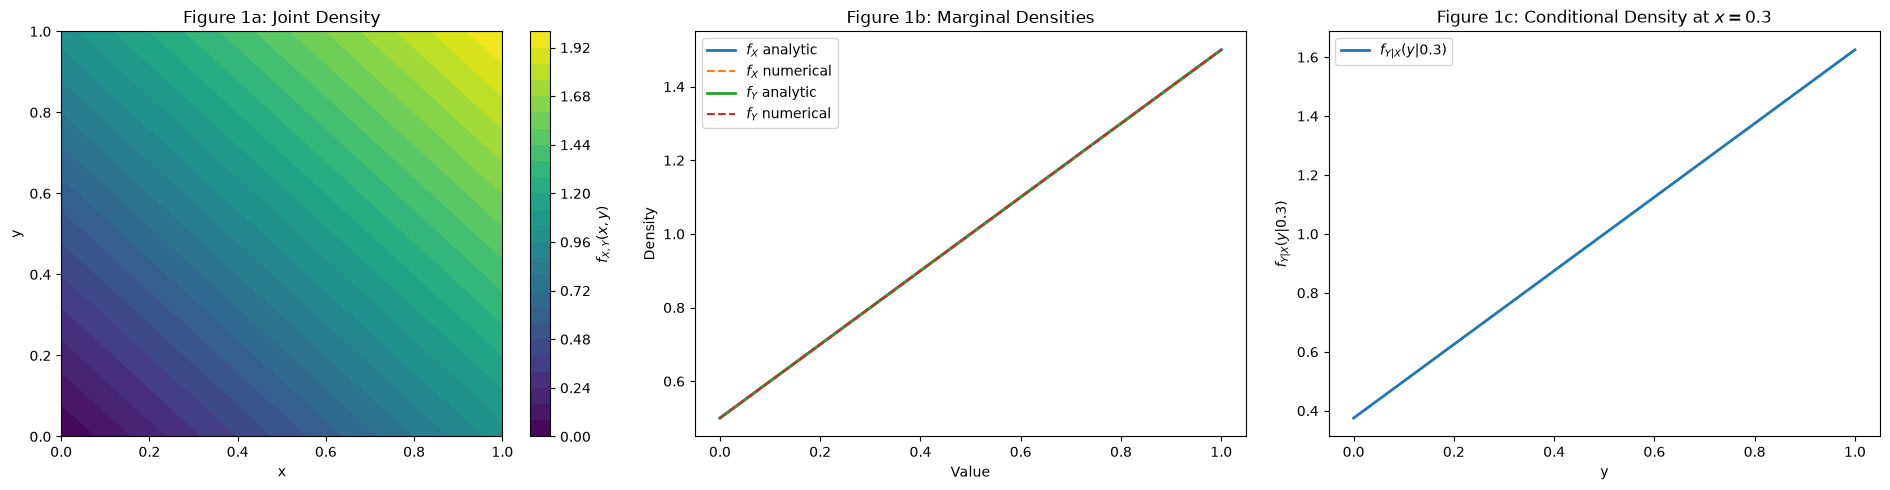

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Panel 1: joint density
contour = axes[0].contourf(
    X_grid,
    Y_grid,
    joint_grid,
    levels=30,
    cmap="viridis"
)

axes[0].set_title("Figure 1a: Joint Density")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
fig.colorbar(contour, ax=axes[0], label=r"$f_{X,Y}(x,y)$")

# Panel 2: marginals
axes[1].plot(
    grid,
    fX_analytic,
    label=r"$f_X$ analytic",
    linewidth=2
)

axes[1].plot(
    grid,
    fX_numeric,
    "--",
    label=r"$f_X$ numerical"
)

axes[1].plot(
    grid,
    fY_analytic,
    label=r"$f_Y$ analytic",
    linewidth=2
)

axes[1].plot(
    grid,
    fY_numeric,
    "--",
    label=r"$f_Y$ numerical"
)

axes[1].set_title("Figure 1b: Marginal Densities")
axes[1].set_xlabel("Value")
axes[1].set_ylabel("Density")
axes[1].legend()

# Panel 3: conditional density
axes[2].plot(
    grid,
    conditional_grid,
    label=r"$f_{Y|X}(y|0.3)$",
    linewidth=2
)

axes[2].set_title(r"Figure 1c: Conditional Density at $x=0.3$")
axes[2].set_xlabel("y")
axes[2].set_ylabel(r"$f_{Y|X}(y|0.3)$")
axes[2].legend()

fig.tight_layout()
plt.show()

## Figure 1 Interpretation

The heatmap shows that the density increases as either variable increases, but the normalized dependence produces a small negative correlation. The numerical marginal curves overlap the analytical curves, and the conditional density integrates to one as required.

In [5]:
N = 10**6
M = 2.0

accepted_chunks = []
accepted_total = 0
proposal_total = 0
batch_size = 2_000_000

while accepted_total < N:
    proposals = rng_step1.uniform(
        0,
        1,
        size=(batch_size, 2)
    )

    uniform_values = rng_step1.uniform(
        0,
        1,
        size=batch_size
    )

    acceptance_probability = (
        proposals[:, 0] + proposals[:, 1]
    ) / M

    accepted = uniform_values <= acceptance_probability

    accepted_chunks.append(proposals[accepted])
    accepted_total += np.count_nonzero(accepted)
    proposal_total += batch_size

samples_step1 = np.vstack(accepted_chunks)[:N]

x_samples = samples_step1[:, 0]
y_samples = samples_step1[:, 1]

acceptance_rate = accepted_total / proposal_total

print(f"Requested samples: {N:,}")
print(f"Total proposals: {proposal_total:,}")
print(f"Acceptance rate: {acceptance_rate:.6f}")
print("The bounding constant is M=2 because x+y <= 2 on the unit square.")

Requested samples: 1,000,000
Total proposals: 4,000,000
Acceptance rate: 0.499963
The bounding constant is M=2 because x+y <= 2 on the unit square.


In [6]:
analytic = {
    "E[X]": 7 / 12,
    "E[Y]": 7 / 12,
    "E[XY]": 1 / 3,
    "Var(X)": 11 / 144,
    "Var(Y)": 11 / 144,
    "Cov(X,Y)": -1 / 144,
    "Correlation": -1 / 11,
}

mean_x = np.mean(x_samples)
mean_y = np.mean(y_samples)
mean_xy = np.mean(x_samples * y_samples)

var_x = np.var(x_samples, ddof=1)
var_y = np.var(y_samples, ddof=1)

cov_xy = np.cov(
    x_samples,
    y_samples,
    ddof=1
)[0, 1]

correlation = cov_xy / np.sqrt(var_x * var_y)

se_mean_x = np.std(
    x_samples,
    ddof=1
) / np.sqrt(N)

se_mean_y = np.std(
    y_samples,
    ddof=1
) / np.sqrt(N)

se_mean_xy = np.std(
    x_samples * y_samples,
    ddof=1
) / np.sqrt(N)

se_var_x = np.std(
    (x_samples - analytic["E[X]"])**2,
    ddof=1
) / np.sqrt(N)

se_var_y = np.std(
    (y_samples - analytic["E[Y]"])**2,
    ddof=1
) / np.sqrt(N)

se_cov = np.std(
    (x_samples - analytic["E[X]"]) *
    (y_samples - analytic["E[Y]"]),
    ddof=1
) / np.sqrt(N)

rho = analytic["Correlation"]

gradient_cov = 1 / np.sqrt(
    analytic["Var(X)"] *
    analytic["Var(Y)"]
)

gradient_var_x = -rho / (
    2 * analytic["Var(X)"]
)

gradient_var_y = -rho / (
    2 * analytic["Var(Y)"]
)

influence_rho = (
    gradient_cov
    * (
        (x_samples - analytic["E[X]"]) *
        (y_samples - analytic["E[Y]"])
        - analytic["Cov(X,Y)"]
    )
    + gradient_var_x
    * (
        (x_samples - analytic["E[X]"])**2
        - analytic["Var(X)"]
    )
    + gradient_var_y
    * (
        (y_samples - analytic["E[Y]"])**2
        - analytic["Var(Y)"]
    )
)

se_correlation = np.std(
    influence_rho,
    ddof=1
) / np.sqrt(N)

sample_results = [
    ("E[X]", mean_x, se_mean_x),
    ("E[Y]", mean_y, se_mean_y),
    ("E[XY]", mean_xy, se_mean_xy),
    ("Var(X)", var_x, se_var_x),
    ("Var(Y)", var_y, se_var_y),
    ("Cov(X,Y)", cov_xy, se_cov),
    ("Correlation", correlation, se_correlation),
]

for name, estimate, standard_error in sample_results:
    difference = estimate - analytic[name]

    print(
        f"{name}: "
        f"estimate={estimate:.10f}, "
        f"analytic={analytic[name]:.10f}, "
        f"difference={difference:.3e}, "
        f"SE={standard_error:.3e}"
    )

E[X]: estimate=0.5831894622, analytic=0.5833333333, difference=-1.439e-04, SE=2.763e-04
E[Y]: estimate=0.5842683620, analytic=0.5833333333, difference=9.350e-04, SE=2.762e-04
E[XY]: estimate=0.3337833403, analytic=0.3333333333, difference=4.500e-04, SE=2.357e-04
Var(X): estimate=0.0763510136, analytic=0.0763888889, difference=-3.788e-05, SE=7.631e-05
Var(Y): estimate=0.0763119655, analytic=0.0763888889, difference=-7.692e-05, SE=7.620e-05
Cov(X,Y): estimate=-0.0069558185, analytic=-0.0069444444, difference=-1.137e-05, SE=7.480e-05
Correlation: estimate=-0.0911264642, analytic=-0.0909090909, difference=-2.174e-04, SE=9.708e-04


The density is slightly negatively correlated because, relative to the product of its marginals, it places more probability on cases where one variable is relatively high while the other is relatively low. The numerical statistics should agree with the analytical values within their reported standard errors.

# Step 2: Uncorrelated Does Not Mean Independent

Let

$$
X\sim \operatorname{Uniform}(-1,1),
\qquad
Y=X^2.
$$

Although \(X\) and \(Y\) are perfectly dependent, their covariance is zero.

## Analytical Results

Since \(X\) is uniform from \(-1\) to \(1\), its distribution is symmetric around zero. Therefore,

$$
E[X]=0
$$

and

$$
E[X^3]=0.
$$

Because \(Y=X^2\),

$$
E[Y]=E[X^2]=\frac13.
$$

Also,

$$
E[XY]=E[X^3]=0.
$$

Therefore,

$$
\operatorname{Cov}(X,Y)
=E[XY]-E[X]E[Y]
=0.
$$

The variances are

$$
\operatorname{Var}(X)=\frac13
$$

and

$$
\operatorname{Var}(Y)
=E[X^4]-E[X^2]^2
=\frac15-\frac19
=\frac4{45}.
$$

Even though the covariance is zero, \(Y=X^2\) is still completely determined by \(X\). Therefore, \(X\) and \(Y\) are dependent even though they are uncorrelated.

In [7]:
N_step2 = 10**7

X_step2 = rng_step2.uniform(
    -1,
    1,
    size=N_step2
)

Y_step2 = X_step2**2

mean_x_step2 = np.mean(X_step2)
mean_y_step2 = np.mean(Y_step2)

var_x_step2 = np.mean(
    (X_step2 - mean_x_step2)**2
)

var_y_step2 = np.mean(
    (Y_step2 - mean_y_step2)**2
)

cov_xy_step2 = np.mean(
    (X_step2 - mean_x_step2) *
    (Y_step2 - mean_y_step2)
)

correlation_step2 = cov_xy_step2 / np.sqrt(
    var_x_step2 * var_y_step2
)

# Delta-method standard error for the sample correlation
influence_correlation = (
    X_step2 * (Y_step2 - 1 / 3)
    / np.sqrt((1 / 3) * (4 / 45))
)

correlation_se_step2 = np.std(
    influence_correlation,
    ddof=1
) / np.sqrt(N_step2)

print(f"Number of samples: {N_step2:,}")
print(f"Sample E[X]: {mean_x_step2:.10f}")
print(f"Sample E[Y]: {mean_y_step2:.10f}")
print(f"Sample Var(X): {var_x_step2:.10f}")
print(f"Sample Var(Y): {var_y_step2:.10f}")
print(f"Sample Cov(X,Y): {cov_xy_step2:.10e}")
print(f"Sample correlation: {correlation_step2:.10e}")
print(f"Correlation standard error: {correlation_se_step2:.10e}")
print(
    f"Correlation divided by standard error: "
    f"{correlation_step2 / correlation_se_step2:.3f}"
)

Number of samples: 10,000,000
Sample E[X]: -0.0000500221
Sample E[Y]: 0.3332498035
Sample Var(X): 0.3332498010
Sample Var(Y): 0.0888573365
Sample Cov(X,Y): 6.3629927208e-06
Sample correlation: 3.6976843179e-05
Correlation standard error: 3.9628041975e-04
Correlation divided by standard error: 0.093


In [8]:
number_of_bins = 1000
bin_edges = np.linspace(-1, 1, number_of_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

bin_indices = np.searchsorted(
    bin_edges,
    X_step2,
    side="right"
) - 1

bin_indices = np.clip(
    bin_indices,
    0,
    number_of_bins - 1
)

bin_counts = np.bincount(
    bin_indices,
    minlength=number_of_bins
)

bin_sums = np.bincount(
    bin_indices,
    weights=Y_step2,
    minlength=number_of_bins
)

bin_squared_sums = np.bincount(
    bin_indices,
    weights=Y_step2**2,
    minlength=number_of_bins
)

conditional_variance = np.full(
    number_of_bins,
    np.nan
)

valid_bins = bin_counts > 1

conditional_variance[valid_bins] = (
    bin_squared_sums[valid_bins]
    - bin_sums[valid_bins]**2 / bin_counts[valid_bins]
) / (bin_counts[valid_bins] - 1)

conditional_variance = np.maximum(
    conditional_variance,
    0
)

print(
    f"Maximum binned conditional variance: "
    f"{np.nanmax(conditional_variance):.10e}"
)

print(
    f"Median binned conditional variance: "
    f"{np.nanmedian(conditional_variance):.10e}"
)

Maximum binned conditional variance: 1.3447016989e-06
Median binned conditional variance: 3.3405608000e-07


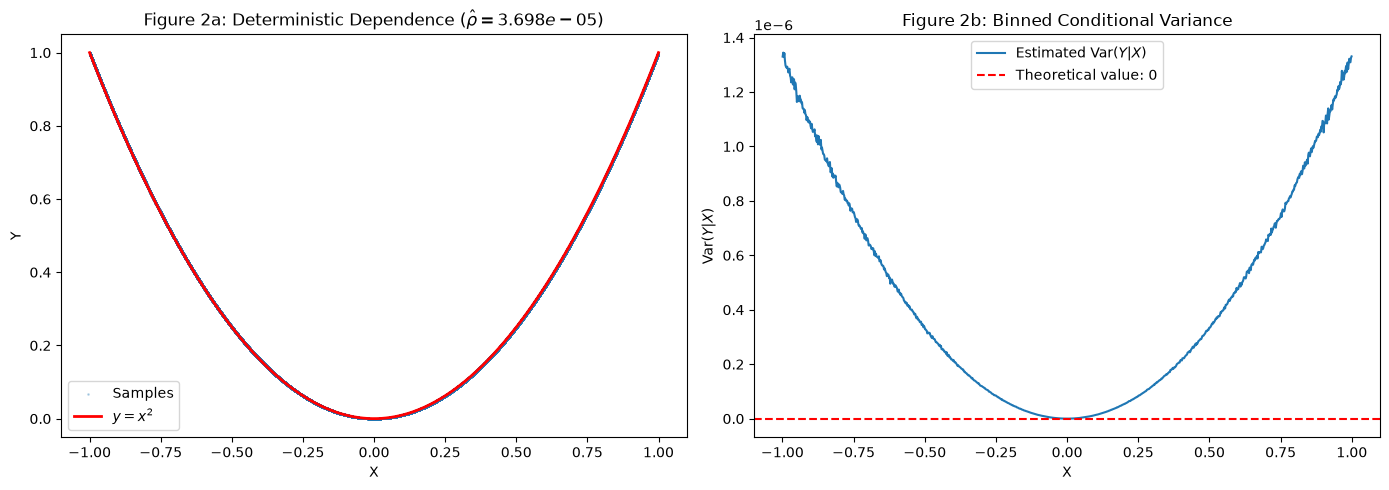

In [9]:
plot_count = 100_000

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Panel 1: scatter plot
axes[0].scatter(
    X_step2[:plot_count],
    Y_step2[:plot_count],
    s=1,
    alpha=0.25,
    label="Samples"
)

x_curve = np.linspace(-1, 1, 500)

axes[0].plot(
    x_curve,
    x_curve**2,
    color="red",
    linewidth=2,
    label=r"$y=x^2$"
)

axes[0].set_title(
    f"Figure 2a: Deterministic Dependence "
    f"($\\hat{{\\rho}}={correlation_step2:.3e}$)"
)

axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].legend()

# Panel 2: binned conditional variance
axes[1].plot(
    bin_centers,
    conditional_variance,
    label=r"Estimated $\operatorname{Var}(Y|X)$"
)

axes[1].axhline(
    0,
    color="red",
    linestyle="--",
    label="Theoretical value: 0"
)

axes[1].set_title(
    "Figure 2b: Binned Conditional Variance"
)

axes[1].set_xlabel("X")
axes[1].set_ylabel(r"$\operatorname{Var}(Y|X)$")
axes[1].ticklabel_format(
    axis="y",
    style="scientific",
    scilimits=(0, 0)
)
axes[1].legend()

fig.tight_layout()
plt.show()

## Figure 2 Interpretation

The points in the scatter plot fall exactly on the curve \(Y=X^2\). This shows that \(Y\) can be determined perfectly if \(X\) is known.

The estimated conditional variances are very close to zero. They are not exactly zero because each bin contains a small range of \(X\)-values instead of only one exact value. Using narrower bins makes the estimated variances even closer to zero.

The correlation is close to zero because the positive and negative values of \(X\) cancel each other when calculating covariance. This shows that correlation only measures linear relationships and can miss nonlinear relationships like \(Y=X^2\).

In [10]:
# Free memory from the first experiment before generating
# another 10^7-sample dataset.
del X_step2
del Y_step2
del bin_indices
del bin_counts
del bin_sums
del bin_squared_sums
del conditional_variance

gaussian_samples_step2 = rng_step2.multivariate_normal(
    mean=np.zeros(2),
    cov=np.eye(2),
    size=N_step2
)

GX_step2 = gaussian_samples_step2[:, 0]
GY_step2 = gaussian_samples_step2[:, 1]

del gaussian_samples_step2

histogram_edges = np.r_[
    -np.inf,
    np.linspace(-4, 4, 41),
    np.inf
]

joint_counts, _, _ = np.histogram2d(
    GX_step2,
    GY_step2,
    bins=(histogram_edges, histogram_edges)
)

x_counts, _ = np.histogram(
    GX_step2,
    bins=histogram_edges
)

y_counts, _ = np.histogram(
    GY_step2,
    bins=histogram_edges
)

empirical_joint_probability = joint_counts / N_step2

empirical_product_probability = (
    x_counts[:, None] * y_counts[None, :]
) / N_step2**2

absolute_difference = np.abs(
    empirical_joint_probability
    - empirical_product_probability
)

total_variation_distance = 0.5 * np.sum(
    absolute_difference
)

maximum_bin_difference = np.max(
    absolute_difference
)

print(
    f"Total variation distance between joint and product: "
    f"{total_variation_distance:.6e}"
)

print(
    f"Maximum binned probability difference: "
    f"{maximum_bin_difference:.6e}"
)

Total variation distance between joint and product: 2.927038e-03
Maximum binned probability difference: 5.533373e-05


## Gaussian Independence Check

The jointly Gaussian pair has zero correlation, so its two variables should be independent. To check this, the empirical joint probabilities were compared with the product of the empirical marginal probabilities.

The two distributions are very close. The small difference is caused by random sampling, so the results support the fact that zero correlation implies independence for jointly Gaussian variables.

For general random variables, being uncorrelated does not necessarily mean being independent. Covariance only measures whether two variables have a linear relationship, so it can miss nonlinear relationships.

For jointly Gaussian variables, the covariance matrix contains all of the dependence information. Therefore, if the correlation is zero, the variables are independent. This is useful in engineering because many estimation and modeling methods rely on the measurements being approximately Gaussian.

# Step 3: The Covariance Matrix and How Well You Can Estimate It

In this step, we use a four-dimensional covariance matrix to study how accurately covariance can be estimated from random samples. We will compare the estimation error for different sample sizes and check whether the error decreases at the expected rate.

## Covariance Matrix Setup

The covariance matrix used in this step is

$$
\Sigma=
\begin{bmatrix}
4 & 2 & 1 & 0\\
2 & 5 & 2 & 1\\
1 & 2 & 3 & 1\\
0 & 1 & 1 & 2
\end{bmatrix}.
$$

The matrix must be symmetric and positive semidefinite in order to be a valid covariance matrix.

In [11]:
Sigma_step3 = np.array([
    [4, 2, 1, 0],
    [2, 5, 2, 1],
    [1, 2, 3, 1],
    [0, 1, 1, 2]
], dtype=float)

mu_step3 = np.zeros(4)

eigenvalues_step3, eigenvectors_step3 = np.linalg.eigh(
    Sigma_step3
)

determinant_step3 = np.linalg.det(Sigma_step3)

print("Covariance matrix:")
print(Sigma_step3)

print("\nEigenvalues:")
for index, value in enumerate(eigenvalues_step3):
    print(f"lambda_{index + 1} = {value:.10f}")

print(f"\nDeterminant: {determinant_step3:.10f}")
print(
    f"Symmetric: "
    f"{np.allclose(Sigma_step3, Sigma_step3.T)}"
)
print(
    f"Valid covariance: "
    f"{is_valid_covariance(Sigma_step3)}"
)

Covariance matrix:
[[4. 2. 1. 0.]
 [2. 5. 2. 1.]
 [1. 2. 3. 1.]
 [0. 1. 1. 2.]]

Eigenvalues:
lambda_1 = 1.2648788942
lambda_2 = 1.7881953127
lambda_3 = 3.0980843219
lambda_4 = 7.8488414713

Determinant: 55.0000000000
Symmetric: True
Valid covariance: True


## Testing the Covariance Validation Function

The function should return `True` for the given covariance matrix. It should return `False` for a nonsymmetric matrix and for a symmetric matrix with a negative eigenvalue.

In [12]:
nonsymmetric_matrix = np.array([
    [1, 2],
    [0, 1]
], dtype=float)

negative_eigenvalue_matrix = np.array([
    [1, 0],
    [0, -0.5]
], dtype=float)

print(
    "Given matrix:",
    is_valid_covariance(Sigma_step3)
)

print(
    "Nonsymmetric matrix:",
    is_valid_covariance(nonsymmetric_matrix)
)

print(
    "Matrix with a negative eigenvalue:",
    is_valid_covariance(negative_eigenvalue_matrix)
)

print("\nEigenvalues of the negative-eigenvalue matrix:")
print(np.linalg.eigh(negative_eigenvalue_matrix)[0])

Given matrix: True
Nonsymmetric matrix: False
Matrix with a negative eigenvalue: False

Eigenvalues of the negative-eigenvalue matrix:
[-0.5  1. ]


## Covariance Estimates for Different Sample Sizes

Samples are generated from a four-dimensional Gaussian distribution with mean zero and covariance matrix \(\Sigma\). For each sample size, the Frobenius norm of the difference between the estimated covariance and the true covariance is calculated.

The Frobenius norm is

$$
\left\|\widehat{\Sigma}-\Sigma\right\|_F
=
\sqrt{
\sum_{i,j}
\left(
\widehat{\Sigma}_{ij}-\Sigma_{ij}
\right)^2
}.
$$

In [13]:
sample_sizes_step3 = np.array([
    10**2,
    10**3,
    10**4,
    10**5,
    10**6
])

single_draw_errors_step3 = []

for sample_size in sample_sizes_step3:
    samples = rng_step3.multivariate_normal(
        mean=mu_step3,
        cov=Sigma_step3,
        size=sample_size
    )

    _, estimated_covariance = sample_mean_cov(samples)

    error = np.linalg.norm(
        estimated_covariance - Sigma_step3,
        ord="fro"
    )

    single_draw_errors_step3.append(error)

    print(
        f"N = {sample_size:,}, "
        f"Frobenius error = {error:.10f}"
    )

single_draw_errors_step3 = np.array(
    single_draw_errors_step3
)

N = 100, Frobenius error = 1.1382809205
N = 1,000, Frobenius error = 0.4299013595
N = 10,000, Frobenius error = 0.1455729504
N = 100,000, Frobenius error = 0.0527204632
N = 1,000,000, Frobenius error = 0.0187766882


## Averaged Covariance Estimation Error

A single simulation at each sample size can be unusually high or low because of random variation. To see the general trend more clearly, the experiment is repeated many times and the errors are averaged.

The required numbers of repetitions are used for each sample size.

In [14]:
repetition_counts_step3 = {
    10**2: 200,
    10**3: 200,
    10**4: 100,
    10**5: 30,
    10**6: 10
}

average_errors_step3 = []
standard_deviations_step3 = []
standard_errors_step3 = []

for sample_size in sample_sizes_step3:
    errors_for_size = []

    for _ in range(repetition_counts_step3[sample_size]):
        samples = rng_step3.multivariate_normal(
            mean=mu_step3,
            cov=Sigma_step3,
            size=sample_size
        )

        _, estimated_covariance = sample_mean_cov(samples)

        error = np.linalg.norm(
            estimated_covariance - Sigma_step3,
            ord="fro"
        )

        errors_for_size.append(error)

    errors_for_size = np.array(errors_for_size)

    average_error = np.mean(errors_for_size)
    standard_deviation = np.std(
        errors_for_size,
        ddof=1
    )

    standard_error = (
        standard_deviation
        / np.sqrt(len(errors_for_size))
    )

    average_errors_step3.append(average_error)
    standard_deviations_step3.append(standard_deviation)
    standard_errors_step3.append(standard_error)

    print(
        f"N = {sample_size:,}, "
        f"repetitions = {len(errors_for_size)}, "
        f"average error = {average_error:.10f}, "
        f"standard deviation = {standard_deviation:.10f}, "
        f"standard error = {standard_error:.10f}, "
        f"sqrt(N)*error = "
        f"{np.sqrt(sample_size) * average_error:.10f}"
    )

average_errors_step3 = np.array(
    average_errors_step3
)

standard_deviations_step3 = np.array(
    standard_deviations_step3
)

standard_errors_step3 = np.array(
    standard_errors_step3
)

N = 100, repetitions = 200, average error = 1.5380964199, standard deviation = 0.4902543884, standard error = 0.0346662203, sqrt(N)*error = 15.3809641986
N = 1,000, repetitions = 200, average error = 0.4903160849, standard deviation = 0.1794388020, standard error = 0.0126882394, sqrt(N)*error = 15.5051560167
N = 10,000, repetitions = 100, average error = 0.1639154810, standard deviation = 0.0542429124, standard error = 0.0054242912, sqrt(N)*error = 16.3915480986
N = 100,000, repetitions = 30, average error = 0.0469080011, standard deviation = 0.0224506781, standard error = 0.0040989143, sqrt(N)*error = 14.8336123923
N = 1,000,000, repetitions = 10, average error = 0.0146042161, standard deviation = 0.0038476632, standard error = 0.0012167379, sqrt(N)*error = 14.6042160687


In [15]:
log_sample_sizes = np.log10(sample_sizes_step3)
log_average_errors = np.log10(average_errors_step3)

slope_step3, intercept_step3 = np.polyfit(
    log_sample_sizes,
    log_average_errors,
    1
)

fitted_errors_step3 = 10**(
    intercept_step3
    + slope_step3 * log_sample_sizes
)

print(
    f"Fitted log-log slope: "
    f"{slope_step3:.10f}"
)

print(
    f"Expected slope for 1/sqrt(N): "
    f"{-0.5:.10f}"
)

print("\nSingle-draw errors:")
for sample_size, error in zip(
    sample_sizes_step3,
    single_draw_errors_step3
):
    print(
        f"N = {sample_size:,}, "
        f"error = {error:.10f}"
    )

print("\nAveraged errors:")
for sample_size, error, standard_error in zip(
    sample_sizes_step3,
    average_errors_step3,
    standard_errors_step3
):
    print(
        f"N = {sample_size:,}, "
        f"average error = {error:.10f}, "
        f"standard error = {standard_error:.10f}"
    )

Fitted log-log slope: -0.5064239837
Expected slope for 1/sqrt(N): -0.5000000000

Single-draw errors:
N = 100, error = 1.1382809205
N = 1,000, error = 0.4299013595
N = 10,000, error = 0.1455729504
N = 100,000, error = 0.0527204632
N = 1,000,000, error = 0.0187766882

Averaged errors:
N = 100, average error = 1.5380964199, standard error = 0.0346662203
N = 1,000, average error = 0.4903160849, standard error = 0.0126882394
N = 10,000, average error = 0.1639154810, standard error = 0.0054242912
N = 100,000, average error = 0.0469080011, standard error = 0.0040989143
N = 1,000,000, average error = 0.0146042161, standard error = 0.0012167379


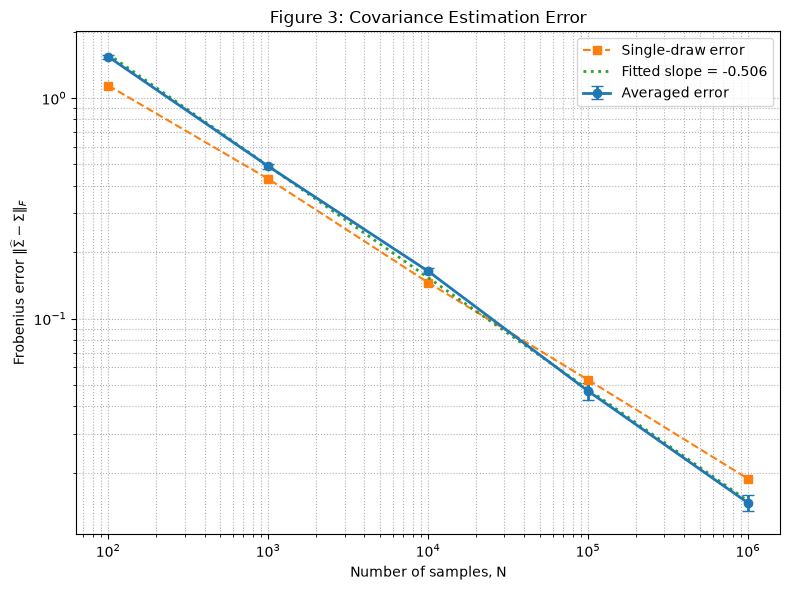

In [16]:
fig, axis = plt.subplots(
    figsize=(8, 6)
)

axis.errorbar(
    sample_sizes_step3,
    average_errors_step3,
    yerr=standard_errors_step3,
    fmt="o-",
    capsize=4,
    linewidth=2,
    label="Averaged error"
)

axis.loglog(
    sample_sizes_step3,
    single_draw_errors_step3,
    "s--",
    linewidth=1.5,
    label="Single-draw error"
)

axis.loglog(
    sample_sizes_step3,
    fitted_errors_step3,
    ":",
    linewidth=2,
    label=f"Fitted slope = {slope_step3:.3f}"
)

axis.set_title(
    "Figure 3: Covariance Estimation Error"
)

axis.set_xlabel("Number of samples, N")
axis.set_ylabel(
    r"Frobenius error "
    r"$\|\widehat{\Sigma}-\Sigma\|_F$"
)

axis.grid(
    True,
    which="both",
    linestyle=":"
)

axis.legend()
fig.tight_layout()
plt.show()

## Figure 3 Interpretation

The averaged error decreases as the number of samples increases. The fitted slope should be close to \(-0.5\), which agrees with an error that decreases approximately like \(1/\sqrt{N}\).

The averaged curve is more useful than the single-draw curve because averaging reduces the random fluctuations from individual simulations. The quantity \(\sqrt{N}\) times the averaged error should stay roughly constant if the expected \(1/\sqrt{N}\) relationship is correct.

## Number of Covariance Parameters

A symmetric \(d\times d\) covariance matrix has

$$
\frac{d(d+1)}{2}
$$

unique parameters because the entries above and below the diagonal are the same.

In [17]:
dimension_4 = 4
dimension_100 = 100

parameters_4 = dimension_4 * (dimension_4 + 1) // 2
parameters_100 = dimension_100 * (dimension_100 + 1) // 2

reference_sample_size = 10**4

estimated_sample_size_100 = (
    reference_sample_size
    * parameters_100
    / parameters_4
)

print(
    f"Free parameters for d={dimension_4}: "
    f"{parameters_4}"
)

print(
    f"Free parameters for d={dimension_100}: "
    f"{parameters_100}"
)

print(
    f"Approximate samples needed for d={dimension_100} "
    f"to match the relative accuracy at N={reference_sample_size:,}: "
    f"{estimated_sample_size_100:,.0f}"
)

Free parameters for d=4: 10
Free parameters for d=100: 5050
Approximate samples needed for d=100 to match the relative accuracy at N=10,000: 5,050,000


A radar with many array elements has a large covariance matrix with many unique entries. If there are not enough measurements, the estimated covariance matrix can be noisy and lead to poor beamforming or detection performance.

One possible solution is to collect more measurements. Another option is to use shrinkage or diagonal loading so that the covariance estimate is more stable.

# Bonus A: Generating Correlated Vectors from Scratch

In this bonus, correlated Gaussian samples are generated using a standard normal random generator and matrix factorizations. The samples are generated in two ways: using Cholesky decomposition and using eigendecomposition.

## Why the Cholesky Method Works

Let \(z\) be a standard normal vector with covariance \(I\), and let

$$
x=Lz.
$$

The covariance of \(x\) is

$$
\operatorname{Cov}(x)
=
\operatorname{Cov}(Lz)
=
L\operatorname{Cov}(z)L^T.
$$

Since \(\operatorname{Cov}(z)=I\),

$$
\operatorname{Cov}(x)=LIL^T=LL^T.
$$

Therefore, if \(L\) is the Cholesky factor of \(\Sigma\), then \(LL^T=\Sigma\).

## Why the Eigendecomposition Method Works

For a symmetric covariance matrix,

$$
\Sigma=V\Lambda V^T.
$$

Using

$$
A=V\Lambda^{1/2},
$$

we generate

$$
x=Az.
$$

Its covariance is

$$
\operatorname{Cov}(x)
=
AA^T
=
V\Lambda^{1/2}
\left(V\Lambda^{1/2}\right)^T.
$$

This simplifies to

$$
\operatorname{Cov}(x)=V\Lambda V^T=\Sigma.
$$

In [18]:
N_bonus_A = 10**6

Sigma_bonus_2d = np.array([
    [4, 2],
    [2, 4]
], dtype=float)

Sigma_bonus_4d = Sigma_step3.copy()


def covariance_error(samples, target_covariance):
    _, estimated_covariance = sample_mean_cov(samples)

    return np.linalg.norm(
        estimated_covariance - target_covariance,
        ord="fro"
    )

In [19]:
bonus_results = []

bonus_matrices = {
    "2D covariance": Sigma_bonus_2d,
    "4D covariance": Sigma_bonus_4d
}

for matrix_name, target_covariance in bonus_matrices.items():
    dimension = target_covariance.shape[0]

    # Generate standard normal vectors using the assigned generator
    z = rng_bonus_A.standard_normal(
        size=(N_bonus_A, dimension)
    )

    # Cholesky method
    cholesky_factor = np.linalg.cholesky(
        target_covariance
    )

    cholesky_samples = z @ cholesky_factor.T

    cholesky_error = covariance_error(
        cholesky_samples,
        target_covariance
    )

    # Eigendecomposition method
    eigenvalues, eigenvectors = np.linalg.eigh(
        target_covariance
    )

    square_root_eigenvalue_matrix = np.diag(
        np.sqrt(eigenvalues)
    )

    eigen_factor = (
        eigenvectors
        @ square_root_eigenvalue_matrix
    )

    eigen_samples = z @ eigen_factor.T

    eigen_error = covariance_error(
        eigen_samples,
        target_covariance
    )

    bonus_results.append([
        matrix_name,
        cholesky_error,
        eigen_error
    ])

    print(f"\n{matrix_name}")
    print(f"Cholesky covariance error: {cholesky_error:.10f}")
    print(f"Eigendecomposition covariance error: {eigen_error:.10f}")
    print("Eigenvalues:")
    print(eigenvalues)


2D covariance
Cholesky covariance error: 0.0072255888
Eigendecomposition covariance error: 0.0065485664
Eigenvalues:
[2. 6.]

4D covariance
Cholesky covariance error: 0.0194962200
Eigendecomposition covariance error: 0.0151254390
Eigenvalues:
[1.26487889 1.78819531 3.09808432 7.84884147]


In [20]:
print(
    f"{'Matrix':<20}"
    f"{'Cholesky Error':>20}"
    f"{'Eigen Error':>20}"
)

for matrix_name, cholesky_error, eigen_error in bonus_results:
    print(
        f"{matrix_name:<20}"
        f"{cholesky_error:>20.10f}"
        f"{eigen_error:>20.10f}"
    )

Matrix                    Cholesky Error         Eigen Error
2D covariance               0.0072255888        0.0065485664
4D covariance               0.0194962200        0.0151254390


## Comparing the Two Methods

Both methods should produce covariance estimates close to the target covariance matrices. The small errors occur because only a finite number of random samples were used.

Cholesky decomposition is usually the cheaper method for generating samples because it only needs one triangular factor. Eigendecomposition calculates both eigenvalues and eigenvectors, so it usually requires more computation. However, eigendecomposition is useful when we want to understand the principal directions of the covariance matrix.

## Singular Covariance Matrix

A singular covariance matrix is positive semidefinite but not positive definite. Standard Cholesky decomposition requires the matrix to be positive definite, so it should fail for a singular matrix.

In [21]:
singular_covariance = np.array([
    [12, 24],
    [24, 48]
], dtype=float)

singular_eigenvalues, _ = np.linalg.eigh(
    singular_covariance
)

print("Singular covariance matrix:")
print(singular_covariance)

print(
    f"\nDeterminant: "
    f"{np.linalg.det(singular_covariance):.10f}"
)

print("\nEigenvalues:")
print(singular_eigenvalues)

try:
    singular_cholesky_factor = np.linalg.cholesky(
        singular_covariance
    )

    print("\nCholesky factor:")
    print(singular_cholesky_factor)

except np.linalg.LinAlgError as error:
    print("\nCholesky decomposition failed.")
    print(f"Error message: {error}")

Singular covariance matrix:
[[12. 24.]
 [24. 48.]]

Determinant: 0.0000000000

Eigenvalues:
[ 0. 60.]

Cholesky decomposition failed.
Error message: Matrix is not positive definite


The singular covariance matrix has a determinant of zero and at least one eigenvalue equal to zero. Because of this, it is not positive definite.

Cholesky decomposition fails because it requires every pivot to be positive. A singular covariance matrix has no full-rank triangular Cholesky factor, even though it can still represent a valid lower-dimensional random vector.